# Notebook reproductible — prévision de la consommation électrique

**Réalisé par :** Zouaghi Jihed et Eya Gharam  
**Encadré par :** Ahmed Dhouibi

Ce notebook présente les principales étapes Python du projet sans réentraîner les modèles lourds. Les modèles et les métriques ont été calculés dans les scripts Python et R, puis sauvegardés dans `data/`, `results/` et `figures/`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
print(f"Dossier du projet : {ROOT}")

Dossier du projet : c:\Users\pc\Desktop\Data\Processed\R_project


## 1. Chargement et contrôle des données

Le dataset final contient les données RTE agrégées au jour et les variables météorologiques.

In [2]:
dataset = pd.read_csv(DATA_DIR / "dataset_final_2015_2024.csv", parse_dates=["date"])
dataset = dataset.sort_values("date").reset_index(drop=True)

required = [
    "date",
    "consommation_moyenne_mw",
    "temperature_france",
    "eolien_moyen",
]
assert dataset[required].notna().all().all()
assert dataset["date"].is_monotonic_increasing
print(f"Dimensions : {dataset.shape}")
print(f"Période : {dataset['date'].min().date()} à {dataset['date'].max().date()}")
dataset[required].head()

Dimensions : (3653, 35)
Période : 2015-01-01 à 2024-12-31


,date,consommation_moyenne_mw,temperature_france,eolien_moyen
0,2015-01-01,67242.375000,1.533333,2130.291667
1,2015-01-02,69001.895833,3.633333,3288.875000
2,2015-01-03,64094.208333,8.100000,4387.458333
3,2015-01-04,58878.666667,7.766667,1252.541667
4,2015-01-05,71274.979167,1.866667,666.833333


## 2. Statistiques descriptives et série observée

,consommation_mw
count,3653.000000
mean,52700.271501
std,10555.830812
min,35589.166667
25%,44699.708333
50%,49254.645833
75%,60357.958333
max,89600.083333


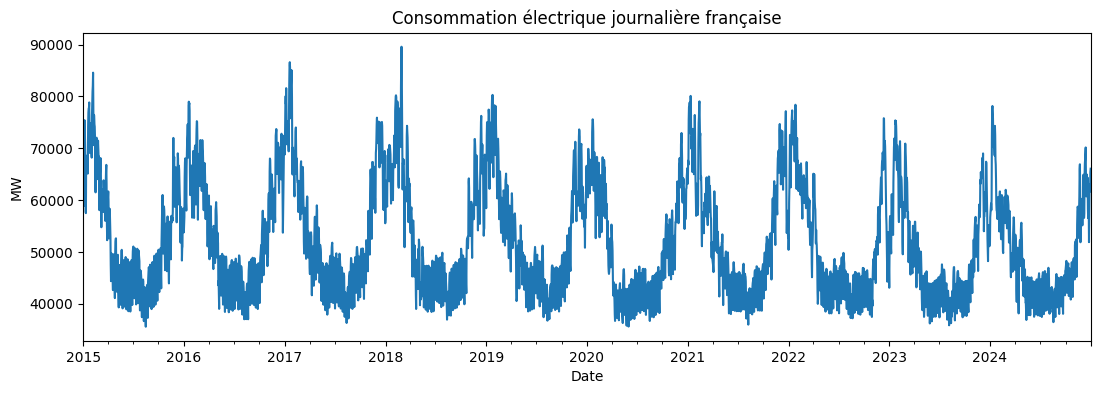

In [3]:
target = dataset["consommation_moyenne_mw"]
display(target.describe().to_frame("consommation_mw"))

ax = dataset.plot(
    x="date",
    y="consommation_moyenne_mw",
    figsize=(13, 4),
    legend=False,
    title="Consommation électrique journalière française",
)
ax.set_xlabel("Date")
ax.set_ylabel("MW")
plt.show()

## 3. Comparaison des modèles à horizon 10 jours

Les métriques sont chargées depuis les fichiers produits par les scripts. Le tableau utilise les quatre métriques demandées : MSE, RMSE, MAE et MAPE.

In [4]:
comparison = pd.read_csv(RESULTS_DIR / "comparaison_finale_horizon_10.csv")
comparison

,rang_RMSE,source,modele,MSE,RMSE,MAE,MAPE,horizon
0,1,Python classique,SARIMAX Python,2.708412e+07,5204.240105,4178.090327,6.537475,10
1,2,R,SARIMAX température + Fourier,3.655661e+07,6046.206160,4853.755318,7.238319,10
2,3,Python réseaux,GRU,5.200111e+07,7211.179587,5143.179518,7.496905,10
3,4,Python réseaux,LSTM,6.002593e+07,7747.640132,5688.246981,8.349342,10
4,5,R,SARIMA automatique,1.069511e+08,10341.716517,7254.478953,10.296262,10
5,6,Python classique,SARIMA Python,1.475043e+08,12145.133745,8833.702786,12.591405,10
6,7,R,Naïf saisonnier hebdomadaire,1.894657e+08,13764.654925,10477.087500,15.169169,10
7,8,Python classique,Naïf saisonnier Python,1.894657e+08,13764.654925,10477.087500,15.169169,10


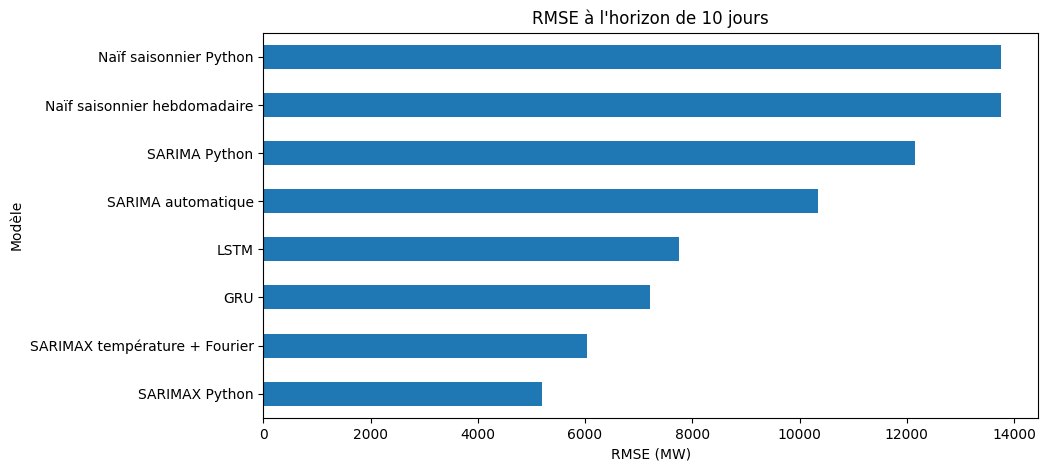

In [5]:
comparison.sort_values("RMSE").plot(
    x="modele",
    y="RMSE",
    kind="barh",
    figsize=(10, 5),
    legend=False,
    title="RMSE à l'horizon de 10 jours",
)
plt.xlabel("RMSE (MW)")
plt.ylabel("Modèle")
plt.show()

## 4. Prévisions classiques et réseaux

Les prévisions ci-dessous ont été générées par `analyse_classique.py` et `reseaux_recurrents.py`.

In [6]:
classical_forecasts = pd.read_csv(
    RESULTS_DIR / "previsions_python_horizon_10.csv",
    parse_dates=["date"],
)
recurrent_forecasts = pd.read_csv(
    RESULTS_DIR / "previsions_reseaux_recurrents.csv",
    parse_dates=["date"],
)

display(classical_forecasts)
display(recurrent_forecasts.head(10))

,horizon,date,observation,SARIMA,naif_saisonnier,SARIMAX,SARIMA_lower_95,SARIMA_upper_95,SARIMAX_lower_95,SARIMAX_upper_95
0,1,2024-01-01,51588.270833,53253.933078,48241.000000,60798.130820,46588.733789,59919.132366,57847.417055,63748.844585
1,2,2024-01-02,56677.604167,54047.318551,53116.791667,60369.822786,44373.736050,63720.901051,56481.054712,64258.590860
2,3,2024-01-03,57490.875000,54398.659504,55172.020833,59888.864751,44121.116197,64676.202810,55432.542704,64345.186797
3,4,2024-01-04,58060.187500,54574.805310,54924.937500,60356.304923,43841.930971,65307.679649,55522.445473,65190.164372
4,5,2024-01-05,59369.312500,54655.342541,53909.541667,60714.496358,43645.569422,65665.115659,55617.988291,65811.004425
5,6,2024-01-06,58064.812500,54694.762213,51115.291667,58085.507794,43444.944901,65944.579524,52801.209808,63369.805780
6,7,2024-01-07,60237.791667,54713.105580,51739.583333,57900.015969,43252.682622,66173.528537,52478.805974,63321.225965
7,8,2024-01-08,72338.083333,54721.966731,48241.000000,68215.769730,43062.013799,66381.919663,62693.172883,73738.366576
8,9,2024-01-09,77525.354167,54726.130226,53116.791667,70628.885278,42874.630583,66577.629868,65030.180603,76227.589952
9,10,2024-01-10,78167.562500,54728.127064,55172.020833,68705.282350,42689.837102,66766.417027,63048.717371,74361.847328


,date,observation,LSTM,GRU
0,2024-01-01,51588.270833,58811.710271,57988.479003
1,2024-01-02,56677.604167,59724.562522,59572.414593
2,2024-01-03,57490.875000,60208.212743,59632.780632
3,2024-01-04,58060.187500,60058.703247,59329.742975
4,2024-01-05,59369.312500,59557.199929,59226.813255
5,2024-01-06,58064.812500,58968.948167,59518.600320
6,2024-01-07,60237.791667,58983.514784,60331.187618
7,2024-01-08,72338.083333,60317.099490,61514.350166
8,2024-01-09,77525.354167,62875.419406,63513.471913
9,2024-01-10,78167.562500,65288.562560,65967.545463


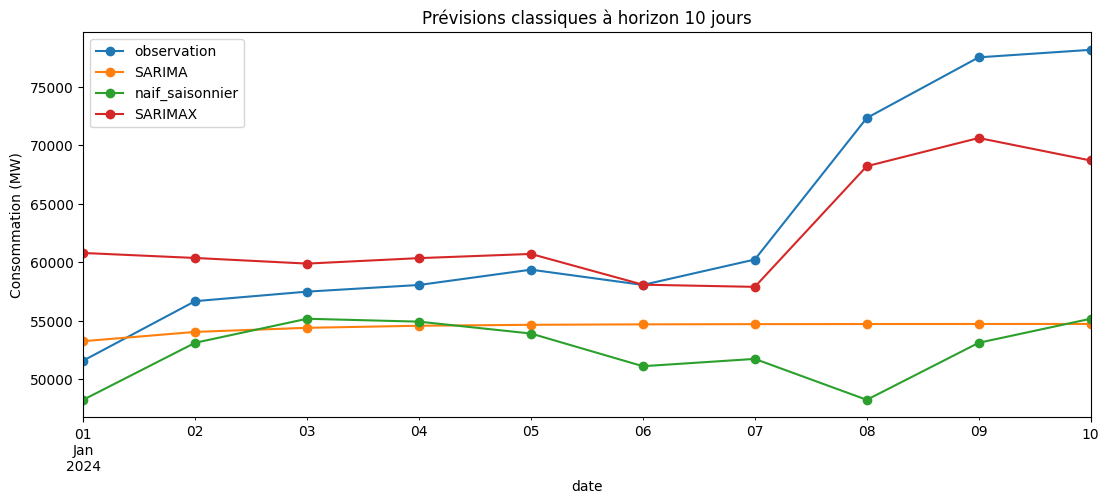

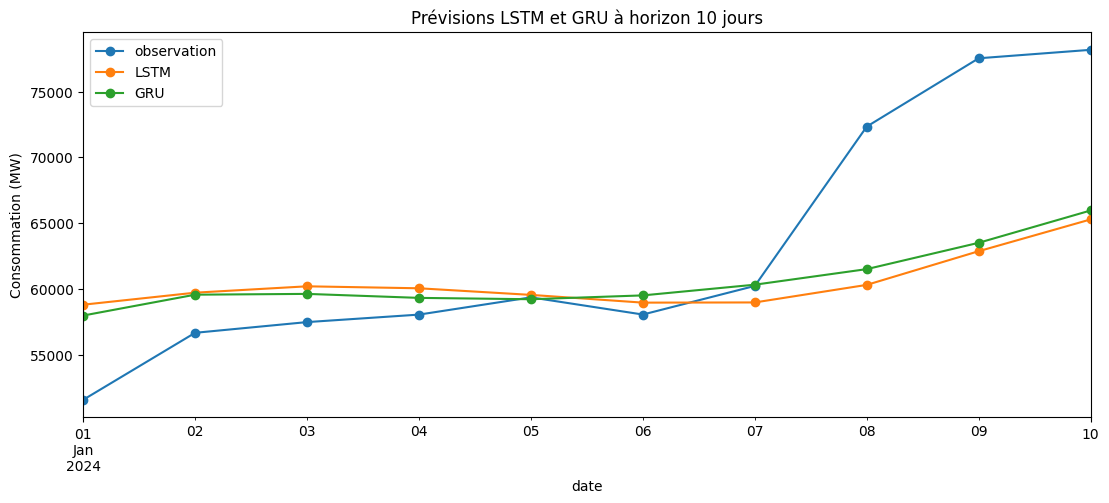

In [7]:
classical_forecasts.set_index("date")[[
    "observation", "SARIMA", "naif_saisonnier", "SARIMAX"
]].plot(figsize=(13, 5), marker="o")
plt.title("Prévisions classiques à horizon 10 jours")
plt.ylabel("Consommation (MW)")
plt.show()

recurrent_forecasts.head(10).set_index("date")[[
    "observation", "LSTM", "GRU"
]].plot(figsize=(13, 5), marker="o")
plt.title("Prévisions LSTM et GRU à horizon 10 jours")
plt.ylabel("Consommation (MW)")
plt.show()

## 5. Conclusion

Dans le tableau final, le SARIMAX Python obtient le meilleur RMSE à l'horizon de 10 jours. Le GRU est meilleur que le LSTM sur ces dix jours, tandis que le classement peut changer sur une période test plus longue. Les résultats doivent être interprétés avec les diagnostics et les limites présentés dans le rapport final.